# Level 2, Task 2: Classification with Logistic Regression
**Codveda Technology | Data Science Internship**

**Task Summary :**

In this notebook I built classification models that predict a category. I worked with two datasets:

- **Part 1: Iris.** Predict the species of a flower (three classes) from its measurements.
- **Part 2: Telecom churn.** Predict whether a customer leaves (two classes), using the training file (`churn-bigml-80.csv`) and the separate test file (`churn-bigml-20.csv`).

For both, I preprocessed the data, trained a logistic regression model, evaluated it with accuracy, precision, recall and the ROC curve, and compared it with a Decision Tree, a Random Forest and an SVM.

## 1.0 Setting Up

### 1.1 Importing the Libraries

In [39]:
import pandas as pd                                    # load and work with data tables
import numpy as np                                     # number work
import matplotlib.pyplot as plt                        # base plotting
import seaborn as sns                                  # pair plot and nicer charts
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold   # split data and cross-validate
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize           # scale features, encode labels
from sklearn.pipeline import make_pipeline             # chain scaling and a model
from sklearn.linear_model import LogisticRegression    # the main model
from sklearn.tree import DecisionTreeClassifier        # comparison model 1
from sklearn.ensemble import RandomForestClassifier    # comparison model 2
from sklearn.svm import SVC                            # comparison model 3
from sklearn.dummy import DummyClassifier              # a "always guess the majority" baseline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, classification_report,
                             ConfusionMatrixDisplay)   # all the evaluation tools

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

**Interpretation:** All the libraries loaded. Besides the models, I import the evaluation tools the task asks for (accuracy, precision, recall, ROC) and a `DummyClassifier`, which I used later as a baseline to see whether my models learn anything useful.

## 2.0 Part 1 (Iris): Loading and Checking the Data

### 2.1 Loading the Dataset

In [40]:
iris = pd.read_csv("iris.csv")      
print("Rows, columns:", iris.shape)
iris.head()

Rows, columns: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Interpretation:** The iris data has 150 flowers (rows) and 5 columns: four measurements (sepal and petal length and width, in cm) and the species. The species is what I want to predict.

### 2.2 Checking Data Quality and Class Balance

In [41]:
print("Missing values:", iris.isnull().sum().sum())
print("Duplicate rows:", iris.duplicated().sum())
print()
print(iris["species"].value_counts())

Missing values: 0
Duplicate rows: 3

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Interpretation:** There are no missing values. There are 3 duplicate rows, which I keep. With only 150 flowers measured to one decimal place, two different flowers can easily have identical measurements, so I do not treat them as errors. I test in step 5.3 whether this choice changes the results. The three species have 50 flowers each, so the classes are perfectly balanced and accuracy is a fair measure for this dataset.


**Interpretation:** There are no missing values, and the three species have 50 flowers each, so the classes are perfectly balanced and accuracy is a fair measure for this dataset. The check finds 3 duplicate rows. I decided to keep them, for these reasons:

1. **They are most likely genuine measurements, not copying errors.** Every row is a separate flower, and its four measurements are recorded in centimetres to only one decimal place. With only 150 flowers and measurements this coarse, it is quite possible for two different flowers to end up with exactly the same numbers.
2. **The repeated rows are consistent with each other.** They form two groups: three setosa flowers that all measure 4.9, 3.1, 1.5 and 0.1, and two virginica flowers that both measure 5.8, 2.7, 5.1 and 1.9. Each group belongs to a single species, so none of the duplicates contradicts another. A data-entry error would be more likely to produce rows that disagree.
3. **This is different from the churn data I did in Level 1.** There, each row is a customer account, and a customer appearing twice would be a real data error that double-counts a person. Here, a repeated row only means two flowers looked identical on the four measurements recorded.
4. **Dropping them would remove real observations from a very small dataset.** It would reduce 150 flowers to 147 and break the perfect balance (setosa would fall to 48 and virginica to 49, while versicolor stays at 50).
5. **They do not affect the results.** The usual reason to remove duplicates is that an identical row in both the training and test sets makes the model look better than it really is. In step 5.3 I tested this: the test accuracy is 0.933 with and without the duplicates, and no test flower has an identical copy in the training set.

For these reasons I keep all 150 rows, and I state the decision here so that it is transparent. Removing them would also have been defensible, and the results would be the same.

### 2.3 Looking at the Species Differences

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa              5.01         3.42          1.46         0.24
versicolor          5.94         2.77          4.26         1.33
virginica           6.59         2.97          5.55         2.03


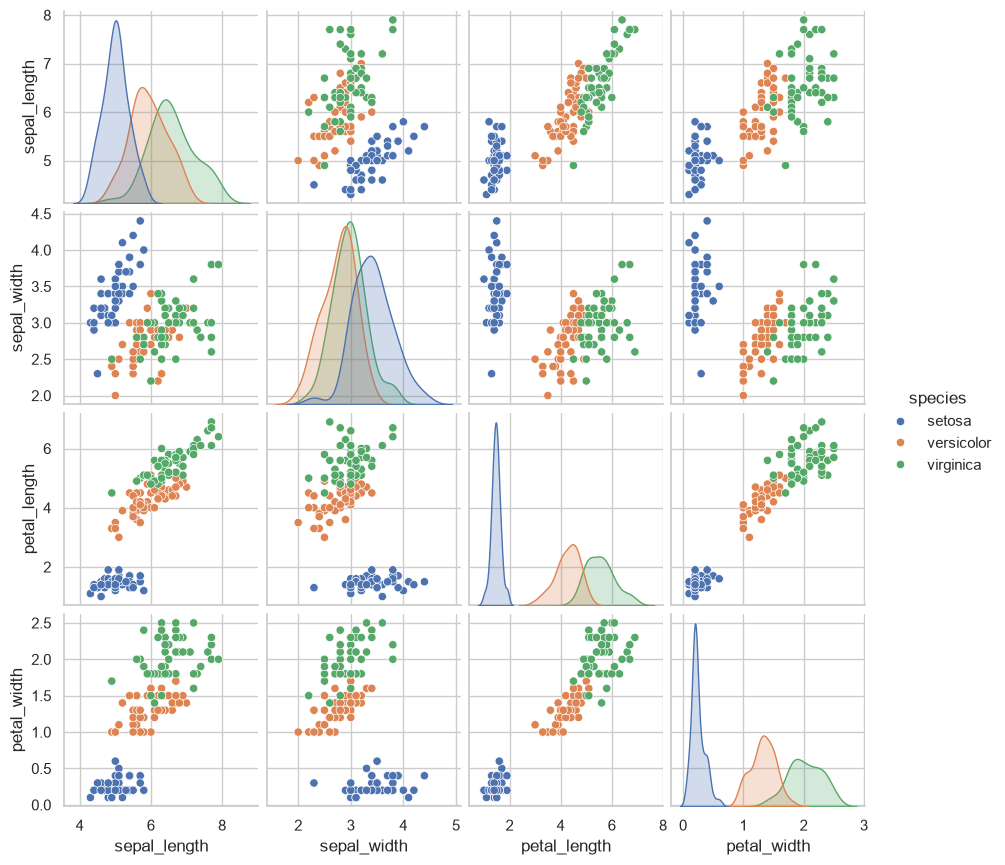

In [42]:
print(iris.groupby("species").mean().round(2))

sns.pairplot(iris, hue="species", height=2.2)
plt.show()

**Interpretation:** The average petal measurements show the difference clearly. Petal length is about 1.5 for setosa, 4.3 for versicolor and 5.6 for virginica, and petal width follows the same order (0.24, 1.33, 2.03). In the pair plot, setosa (blue) sits far away from the other two in almost every chart. Versicolor (orange) and virginica (green) overlap a little, especially on the sepal measurements, but the petal length and petal width separate them well. So I expect setosa to be easy to classify, and the small number of mistakes to be between versicolor and virginica.

## 3.0 Part 1 (Iris): Preprocessing

### 3.1 Encoding the Species Labels

In [43]:
le = LabelEncoder()
y = le.fit_transform(iris["species"])
X = iris.drop(columns="species")

print({name: int(code) for name, code in zip(le.classes_, le.transform(le.classes_))})

{'setosa': 0, 'versicolor': 1, 'virginica': 2}


**Interpretation:** Models work with numbers, so I converted the species names to 0, 1 and 2 (in alphabetical order). I keep the mapping so I can turn predictions back into names later.

### 3.2 Train/Test Split

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps the 3 species balanced in both sets

print("Training:", X_train.shape, "| Testing:", X_test.shape)
print("Test set counts per species:", np.bincount(y_test))

Training: (120, 4) | Testing: (30, 4)
Test set counts per species: [10 10 10]


**Interpretation:** I used 120 flowers for training and 30 for testing. Because I used `stratify=y`, the test set has exactly 10 flowers of each species, so every class is tested fairly.

### 3.3 Scaling the Features

In [45]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)    # learn from the training set only
X_test_s = scaler.transform(X_test)

print("Scaled training means:", X_train_s.mean(axis=0).round(2))

Scaled training means: [-0.  0. -0.  0.]


**Interpretation:** I scaled the four measurements using the training set only. The scaled training means are 0, as expected. Scaling helps logistic regression and SVM, which are sensitive to the size of the numbers.

## 4.0 Part 1 (Iris): Logistic Regression

### 4.1 Training the Model

In [46]:
log_iris = LogisticRegression(max_iter=1000)
log_iris.fit(X_train_s, y_train)

pred_iris = log_iris.predict(X_test_s)
proba_iris = log_iris.predict_proba(X_test_s)
print("Test accuracy:", round(accuracy_score(y_test, pred_iris), 3))

Test accuracy: 0.933


**Interpretation:** The model got 0.933 accuracy on the test set, so it classified 28 of the 30 flowers correctly.

### 4.2 Precision, Recall and F1 for Each Species

In [47]:
print(classification_report(y_test, pred_iris, target_names=le.classes_, digits=3))

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



**Interpretation:** Precision tells me, out of the flowers the model labelled as a species, how many really were that species. Recall tells me, out of the flowers that really are that species, how many the model found. Setosa has 1.000 for everything, so every setosa was found and none was mislabelled. Versicolor and virginica both have precision and recall of 0.900. The F1 score combines precision and recall into one number, and it is 0.933 on average.

### 4.3 Confusion Matrix

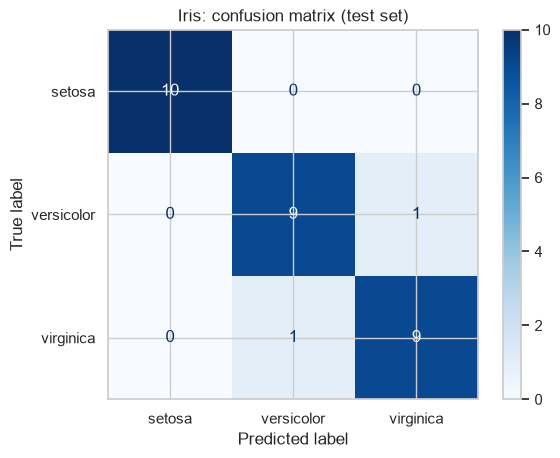

In [48]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_iris, display_labels=le.classes_, cmap="Blues")
plt.title("Iris: confusion matrix (test set)")
plt.show()

**Interpretation:** The diagonal shows the correct predictions (10, 9 and 9). There are only two mistakes: one versicolor was predicted as virginica, and one virginica was predicted as versicolor. Setosa was never confused with anything, which matches what I saw in the pair plot.

### 4.4 ROC Curves

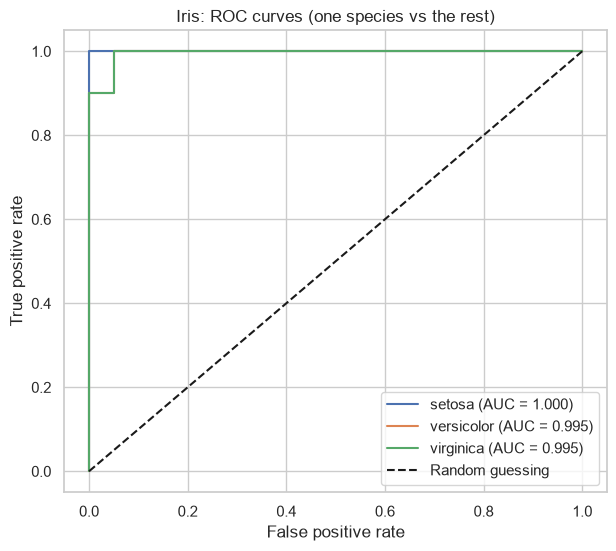

In [49]:
# iris has 3 classes, so I draw one curve per species (that species vs the rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

plt.figure(figsize=(7, 6))
for i, name in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba_iris[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Iris: ROC curves (one species vs the rest)")
plt.legend()
plt.show()

**Interpretation:** Each curve compares one species against the other two. The closer a curve gets to the top-left corner, the better, and the dashed diagonal is what random guessing would give. Setosa has an AUC of 1.000 (perfect), and versicolor and virginica both have 0.995. Those last two curves lie exactly on top of each other, so only the green one is visible. The model ranks the flowers almost perfectly.

## 5.0 Part 1 (Iris): Comparing Classifiers

### 5.1 Training the Other Models

In [50]:
iris_models = {
    "Logistic Regression": log_iris,
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42),
}

rows = {}
for name, m in iris_models.items():
    if name != "Logistic Regression":
        m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    rows[name] = {"Accuracy": accuracy_score(y_test, p),
                  "Precision": precision_score(y_test, p, average="macro"),
                  "Recall": recall_score(y_test, p, average="macro"),
                  "F1": f1_score(y_test, p, average="macro")}
pd.DataFrame(rows).T.round(3)

,Accuracy,Precision,Recall,F1
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.900,0.902,0.900,0.900
Random Forest,0.900,0.902,0.900,0.900
SVM,0.967,0.970,0.967,0.967


**Interpretation:** On this test set, SVM is best (0.967), then logistic regression (0.933), and the Decision Tree and Random Forest are both at 0.900. I should not read too much into this. The test set has only 30 flowers, so one flower is worth 3.3 percentage points, and these differences are only one or two flowers.

### 5.2 Cross-Validation

In [59]:
# the test set has only 30 flowers, so I repeat the test on 5 different splits
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, m in {"Logistic Regression": LogisticRegression(max_iter=1000),
                "Decision Tree": DecisionTreeClassifier(random_state=42),
                "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
                "SVM": SVC(kernel="rbf")}.items():
    s = cross_val_score(make_pipeline(StandardScaler(), m), X, y, cv=skf, scoring="accuracy")
    cv_rows[name] = {"Mean accuracy": s.mean(), "Std": s.std(), "Lowest fold": s.min()}
pd.DataFrame(cv_rows).T.round(3)

,Mean accuracy,Std,Lowest fold
Logistic Regression,0.953,0.045,0.9
Decision Tree,0.953,0.034,0.9
Random Forest,0.960,0.039,0.9
SVM,0.960,0.039,0.9


**Interpretation:** Across five different splits, all four models score between 0.953 and 0.960, which is practically the same. So for the iris data, the choice of model hardly matters, and logistic regression does just as well as the more complex models while being simpler to explain. That is why I would choose it here.

### 5.3 Checking the Effect of the Duplicate Rows

In [60]:
def iris_check(data):
    labels = LabelEncoder().fit_transform(data["species"])
    feats = data.drop(columns="species")
    Xa, Xb, ya, yb = train_test_split(feats, labels, test_size=0.2, random_state=42, stratify=labels)
    sc_check = StandardScaler().fit(Xa)
    model = LogisticRegression(max_iter=1000).fit(sc_check.transform(Xa), ya)
    train_rows = set(map(tuple, Xa.values))
    twins = sum(tuple(r) in train_rows for r in Xb.values)    # test flowers that also appear in training
    return accuracy_score(yb, model.predict(sc_check.transform(Xb))), twins

acc_with, twins_with = iris_check(iris)
acc_without, twins_without = iris_check(iris.drop_duplicates().reset_index(drop=True))

pd.DataFrame([
    {"Version": "With duplicates (150 rows)", "Test accuracy": acc_with, "Test flowers also in training set": twins_with},
    {"Version": "Without duplicates (147 rows)", "Test accuracy": acc_without, "Test flowers also in training set": twins_without},
]).set_index("Version").round(3)

,Test accuracy,Test flowers also in training set
Version,,
With duplicates (150 rows),0.933,0
Without duplicates (147 rows),0.933,0


**Interpretation:** Dropping the 3 duplicate rows does not change the result: the test accuracy is 0.933 with and without them. None of the test flowers has an identical copy in the training set, so the duplicates did not leak into the test score either. This supports my choice in 2.2 to keep them.

## 6.0 Part 2 (Churn): Loading and Preparing the Data

### 6.1 Loading the Training and Test Files

In [61]:
train_raw = pd.read_csv("churn-bigml-80.csv")
test_raw = pd.read_csv("churn-bigml-20.csv")

print("Training file:", train_raw.shape, "| Test file:", test_raw.shape)
print("Same column names:", list(train_raw.columns) == list(test_raw.columns))
print(f"Churn rate, training: {train_raw['Churn'].mean():.1%} | test: {test_raw['Churn'].mean():.1%}")

Training file: (2666, 20) | Test file: (667, 20)
Same column names: True
Churn rate, training: 14.6% | test: 14.2%


**Interpretation:** The training file has 2,666 customers and the test file has 667, with identical columns. The churn rates are similar (14.6% and 14.2%), so the test file is a fair sample of the same kind of customers. I use the two files exactly as supplied: train on the 80 file and test on the 20 file.

### 6.2 Preprocessing Both Files the Same Way

In [62]:
def prepare(df):
    df = df.copy()
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    df["churn"] = df["churn"].astype(int)
    df["international_plan"] = df["international_plan"].map({"No": 0, "Yes": 1})
    df["voice_mail_plan"] = df["voice_mail_plan"].map({"No": 0, "Yes": 1})
    # charge columns repeat the minutes columns, and vmail messages repeat the voice mail plan
    df = df.drop(columns=["total_day_charge", "total_eve_charge", "total_night_charge",
                          "total_intl_charge", "number_vmail_messages", "state"])
    df["area_code"] = df["area_code"].astype(str)
    return pd.get_dummies(df, columns=["area_code"], drop_first=True, dtype=int)

train = prepare(train_raw)
test = prepare(test_raw).reindex(columns=train.columns, fill_value=0)   # same columns, same order

X_tr, y_tr = train.drop(columns="churn"), train["churn"]
X_te, y_te = test.drop(columns="churn"), test["churn"]

print("Features used:", list(X_tr.columns))
print("Training:", X_tr.shape, "| Testing:", X_te.shape)

Features used: ['account_length', 'international_plan', 'voice_mail_plan', 'total_day_minutes', 'total_day_calls', 'total_eve_minutes', 'total_eve_calls', 'total_night_minutes', 'total_night_calls', 'total_intl_minutes', 'total_intl_calls', 'customer_service_calls', 'area_code_415', 'area_code_510']
Training: (2666, 14) | Testing: (667, 14)


**Interpretation:** I applied the same preparation to both files. The two plan columns became 0/1, `area_code` was one-hot encoded (2 new columns), and the rest stayed numeric. I dropped columns that repeat other columns: the four `total_*_charge` columns (identical in information to the minutes columns, as I found in the EDA), `number_vmail_messages` (almost the same as `voice_mail_plan`), and `state`. I dropped state because it would add 50 columns and the EDA suggested that state differences are mostly noise. When I tried it both ways, the model did slightly better without it (AUC 0.825 against 0.807). I also did not remove outliers this time. The test file should be treated like new customers would be, and the customers with many support calls are exactly the signal I want the model to see. This leaves 14 features. `reindex` makes sure the test file has exactly the same columns in the same order as the training file.

### 6.3 Scaling the Features

In [63]:
sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)      # learned from the training file only
X_te_s = sc.transform(X_te)          # the test file is only transformed, never learned from

print("Scaled training means (should be about 0):", X_tr_s.mean().round(3))

Scaled training means (should be about 0): 0.0


**Interpretation:** The scaler learned its averages from the training file only, and the test file was just transformed. This keeps the test results honest, because the model never gets any information from the test customers.

## 7.0 Part 2 (Churn): Logistic Regression

### 7.1 A Baseline to Beat

In [64]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr_s, y_tr)
print("Accuracy if I predict 'stayed' for every customer:", round(accuracy_score(y_te, dummy.predict(X_te_s)), 3))

Accuracy if I predict 'stayed' for every customer: 0.858


**Interpretation:** If I predicted 'stayed' for every customer, I would be right 85.8% of the time without finding a single churner. This is the score any model has to beat, and it shows why accuracy alone is a poor measure when only 14% of customers churn.

### 7.2 Training and Evaluating the Model

In [73]:
def churn_score(model, X):
    # probability of churn; the SVM has no probabilities, so I use its decision score for the ROC curve
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def evaluate(model, X, y):
    pred = model.predict(X)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC AUC": roc_auc_score(y, churn_score(model, X))}

log_churn = LogisticRegression(max_iter=2000)
log_churn.fit(X_tr_s, y_tr)

print(classification_report(y_te, log_churn.predict(X_te_s), target_names=["Stayed", "Churned"], digits=3))
pd.DataFrame({"Logistic Regression": evaluate(log_churn, X_te_s, y_te)}).T.round(3)

              precision    recall  f1-score   support

      Stayed      0.876     0.965     0.918       572
     Churned      0.459     0.179     0.258        95

    accuracy                          0.853       667
   macro avg      0.668     0.572     0.588       667
weighted avg      0.817     0.853     0.824       667



,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.853,0.459,0.179,0.258,0.825


**Interpretation:** The logistic regression has an accuracy of 0.853, which is actually lower than the baseline of 0.858, so accuracy tells me the model is no better than guessing 'stayed'. The other metrics show the real picture. For the churn class, precision is 0.459 (when it says a customer will churn, it is right 46% of the time) and recall is only 0.179 (it finds just 18% of the customers who actually leave). The F1 score is low at 0.258. The ROC AUC of 0.825 is better: it means the model ranks a random churner above a random non-churner 82.5% of the time, so it has learned something, but its default decision rule is too cautious for a rare class.

### 7.3 Confusion Matrix and ROC Curve

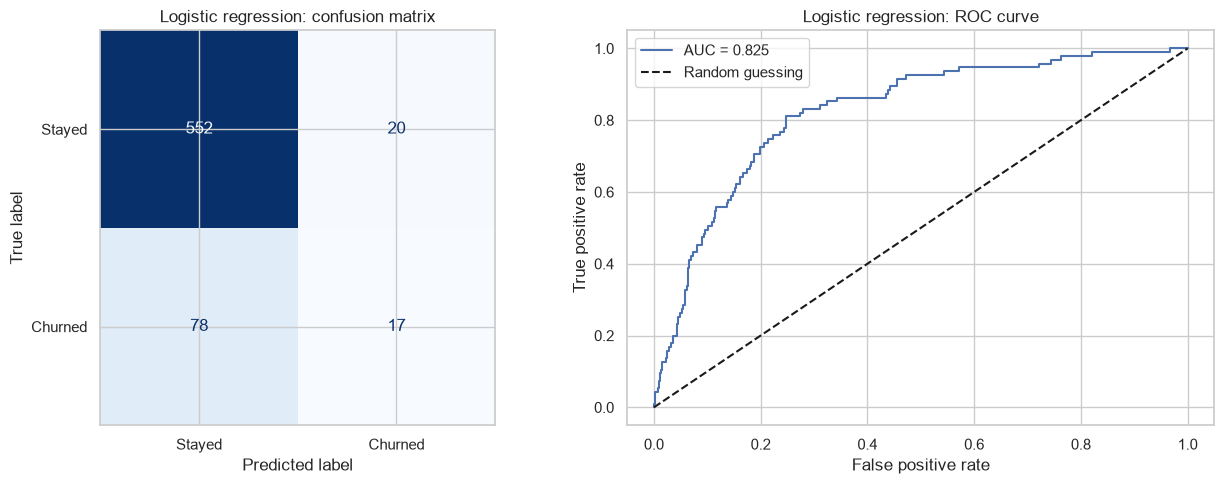

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(y_te, log_churn.predict(X_te_s), display_labels=["Stayed", "Churned"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Logistic regression: confusion matrix")

fpr, tpr, _ = roc_curve(y_te, churn_score(log_churn, X_te_s))
axes[1].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("Logistic regression: ROC curve")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation:** In the confusion matrix, 552 customers who stayed were correctly identified and 20 were wrongly flagged as churners. But 78 of the 95 real churners were missed, and only 17 were caught. The ROC curve sits clearly above the diagonal (AUC 0.825), so there is real signal in the data, even though the model misses most churners at the default setting.

### 7.4 Handling the Class Imbalance

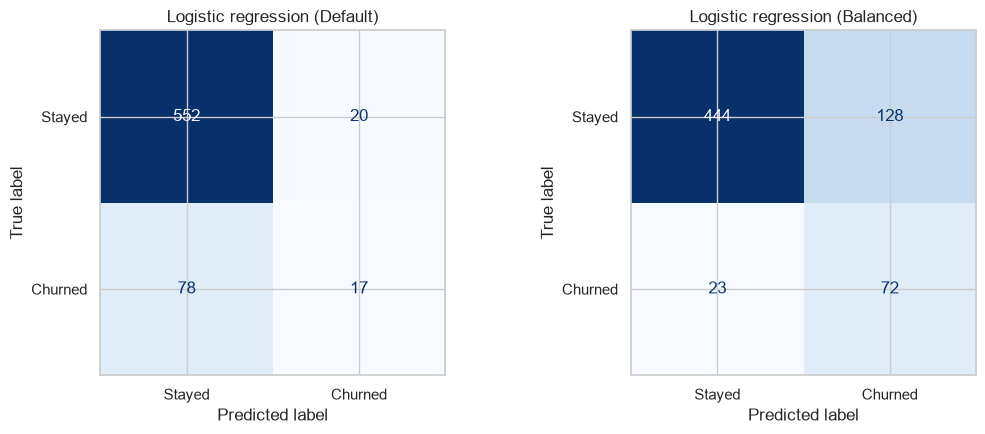

,Accuracy,Precision,Recall,F1,ROC AUC
Default,0.853,0.459,0.179,0.258,0.825
Balanced,0.774,0.360,0.758,0.488,0.829


In [75]:
# class_weight="balanced" makes a missed churner count more during training
log_bal = LogisticRegression(max_iter=2000, class_weight="balanced")
log_bal.fit(X_tr_s, y_tr)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, [("Default", log_churn), ("Balanced", log_bal)]):
    ConfusionMatrixDisplay.from_predictions(y_te, m.predict(X_te_s), display_labels=["Stayed", "Churned"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Logistic regression ({name})")
plt.tight_layout()
plt.show()

pd.DataFrame({"Default": evaluate(log_churn, X_te_s, y_te),
              "Balanced": evaluate(log_bal, X_te_s, y_te)}).T.round(3)

**Interpretation:** Setting `class_weight="balanced"` makes the model treat a missed churner as a bigger mistake. Recall jumps from 0.179 to 0.758 (72 of the 95 churners are now caught, against 17 before), and F1 rises from 0.258 to 0.488. The cost is more false alarms: precision falls to 0.360 (128 loyal customers are flagged), and accuracy drops to 0.774. The AUC hardly changes (0.825 to 0.829), because the model still ranks customers the same way and only the cut-off has moved. Which version is better depends on the business: if losing a customer costs more than contacting someone who would have stayed, the balanced version is the better choice.

### 7.5 What the Model Says About Churn

total_day_minutes         1.97
customer_service_calls    1.94
international_plan        1.88
total_eve_minutes         1.33
total_intl_minutes        1.32
total_night_minutes       1.15
total_day_calls           1.06
total_night_calls         1.04
account_length            1.04
area_code_415             1.00
total_eve_calls           0.98
area_code_510             0.97
total_intl_calls          0.75
voice_mail_plan           0.67
dtype: float64


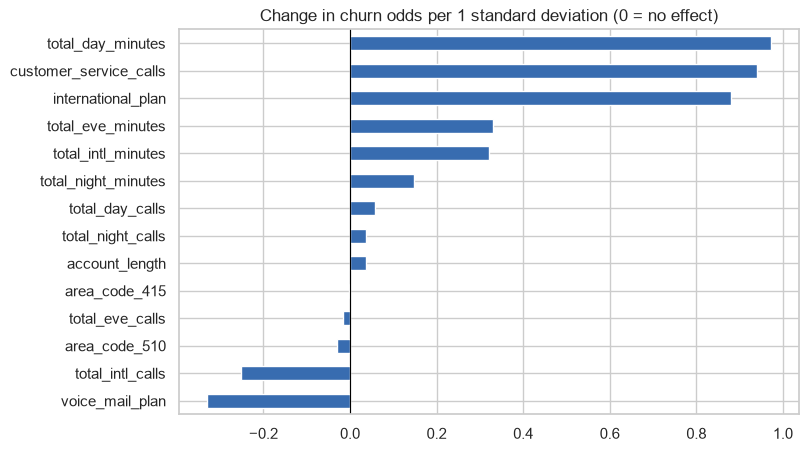

In [76]:
# exp(coefficient) = how many times the odds of churn are multiplied when the feature rises by 1 standard deviation
odds = pd.Series(np.exp(log_churn.coef_[0]), index=X_tr.columns).sort_values(ascending=False)
print(odds.round(2))

(odds - 1).sort_values().plot(kind="barh", color="#386cb0", figsize=(8, 5))
plt.axvline(0, color="black", lw=0.8)
plt.title("Change in churn odds per 1 standard deviation (0 = no effect)")
plt.show()

**Interpretation:** An odds ratio above 1 means churn becomes more likely, and below 1 means less likely, for each increase of one standard deviation in that feature. The biggest risk factors are `total_day_minutes` (1.97, nearly doubling the odds), `customer_service_calls` (1.94) and `international_plan` (1.88). Evening and international minutes also raise the odds (about 1.3). Having a voice mail plan lowers them (0.67). `account_length` and the area codes are close to 1.0, so they have almost no effect. This agrees with what I found in the EDA.

## 8.0 Part 2 (Churn): Comparing Classifiers

### 8.1 Training the Other Models

In [77]:
churn_models = {
    "Logistic Regression": log_churn,
    "Logistic Regression (balanced)": log_bal,
    "Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42),
}

for name, m in churn_models.items():
    if name not in ("Logistic Regression", "Logistic Regression (balanced)"):
        m.fit(X_tr_s, y_tr)

churn_results = pd.DataFrame({name: evaluate(m, X_te_s, y_te) for name, m in churn_models.items()}).T
churn_results.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.853,0.459,0.179,0.258,0.825
Logistic Regression (balanced),0.774,0.360,0.758,0.488,0.829
Decision Tree (depth 5),0.954,0.864,0.800,0.831,0.909
Random Forest,0.942,0.952,0.621,0.752,0.929
SVM,0.912,0.846,0.463,0.599,0.928


**Interpretation:** The three non-linear models are far ahead of logistic regression on the churn class. The Decision Tree has the best F1 (0.831) and recall (0.800), and accuracy of 0.954. The Random Forest has the best precision (0.952) and AUC (0.929), but a lower recall of 0.621. The SVM has a similar AUC (0.928), but its recall is only 0.463. So the 'best' model depends on what I value: catching more churners (the Decision Tree) or having fewer false alarms and the best ranking (the Random Forest).

### 8.2 ROC Curves of All Models

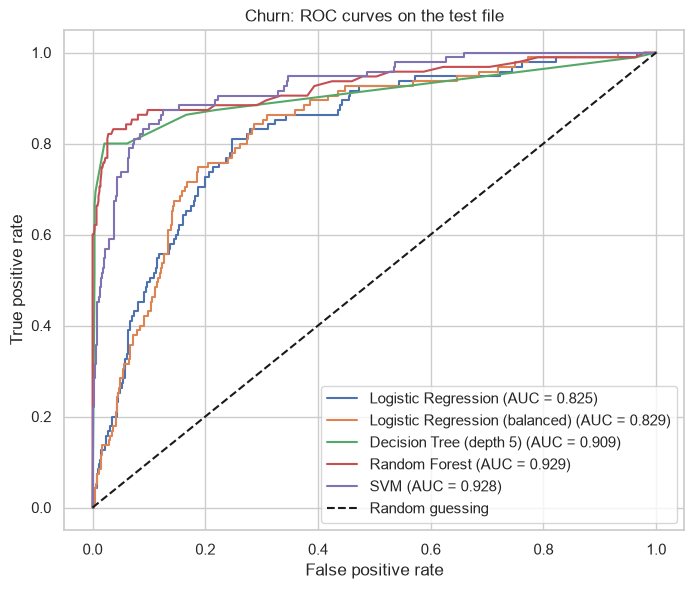

In [78]:
plt.figure(figsize=(8, 6.5))
for name, m in churn_models.items():
    fpr, tpr, _ = roc_curve(y_te, churn_score(m, X_te_s))
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Churn: ROC curves on the test file")
plt.legend(loc="lower right")
plt.show()

**Interpretation:** The Random Forest, SVM and Decision Tree curves rise much more steeply than the two logistic regression curves, with AUCs of 0.93, 0.93 and 0.91 against 0.83. A likely reason is that churn does not change gradually. In the EDA, churn jumped sharply at the fourth customer service call, and a straight-line model like logistic regression cannot represent that kind of jump or the combination of features as well as trees can.

### 8.3 Cross-Validation on the Training File

In [ ]:
# one test file can favour one model by luck, so I repeat the comparison on 5 splits of the training file
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42),
}

cv_out = {}
for name, m in cv_models.items():
    pipe = make_pipeline(StandardScaler(), m)
    f1s = cross_val_score(pipe, X_tr, y_tr, cv=skf5, scoring="f1")
    aucs = cross_val_score(pipe, X_tr, y_tr, cv=skf5, scoring="roc_auc")
    cv_out[name] = {"Mean F1": f1s.mean(), "F1 std": f1s.std(), "Mean AUC": aucs.mean(), "AUC std": aucs.std()}
pd.DataFrame(cv_out).T.round(3)

**Interpretation:** This check shows the Random Forest is the most dependable. Across five splits of the training file it has the best F1 (0.757) and AUC (0.906) with the smallest spread (0.017 for F1). The Decision Tree's F1 of 0.831 on the test file was on the lucky side, because its cross-validated F1 is lower (0.739) and varies more (0.042). The SVM (F1 0.557) and the balanced logistic regression (F1 0.478) are clearly behind.

### 8.4 Confusion Matrices and Important Features

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["Decision Tree (depth 5)", "Random Forest"]):
    ConfusionMatrixDisplay.from_predictions(y_te, churn_models[name].predict(X_te_s),
                                            display_labels=["Stayed", "Churned"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

imp = pd.Series(churn_models["Random Forest"].feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print(imp.round(3).head(6))

**Interpretation:** The Decision Tree caught 76 of the 95 churners but gave 12 false alarms. The Random Forest caught 59 and gave only 3 false alarms, so it is the more cautious of the two. The most important features in the forest are `total_day_minutes` (0.231), `customer_service_calls` (0.122), `total_eve_minutes` (0.098) and `international_plan` (0.089), the same ones that came out in the EDA and in the logistic regression odds ratios.

## 9.0 Conclusion

### 9.1 Results: Iris (Part 1)
| Model | Test accuracy | Cross-validated accuracy |
|---|---|---|
| **Logistic Regression** | 0.933 | 0.953 |
| Decision Tree | 0.900 | 0.953 |
| Random Forest | 0.900 | 0.960 |
| SVM | 0.967 | 0.960 |

### 9.2 Results: Churn (Part 2, trained on the 80 file, tested on the 20 file)
| Model | Accuracy | Precision | Recall | F1 | ROC AUC |
|---|---|---|---|---|---|
| Baseline (always "stayed") | 0.858 | 0 | 0 | 0 | 0.500 |
| Logistic Regression | 0.853 | 0.459 | 0.179 | 0.258 | 0.825 |
| Logistic Regression (balanced) | 0.774 | 0.360 | 0.758 | 0.488 | 0.829 |
| Decision Tree (depth 5) | 0.954 | 0.864 | 0.800 | 0.831 | 0.909 |
| **Random Forest** | 0.942 | 0.952 | 0.621 | 0.752 | 0.929 |
| SVM | 0.912 | 0.846 | 0.463 | 0.599 | 0.928 |

### 9.3 What I Found
1. **Iris is easy.** Logistic regression classifies 28 of 30 test flowers correctly and does as well as the more complex models when cross-validated. The only mistakes are between versicolor and virginica.
2. **Accuracy can mislead.** On the churn data, the plain logistic regression had a lower accuracy than a model that always says "stayed", and it caught only 18% of churners. Precision, recall, F1 and AUC gave the true picture.
3. **Class weights trade false alarms for catches.** Balancing the classes raised recall from 0.18 to 0.76, at the cost of more false alarms.
4. **For churn, non-linear models are clearly better.** The Random Forest has the best AUC and the most stable cross-validated scores, so I would choose it. The Decision Tree catches more churners on the test file but is less stable.
5. **The main churn drivers** are day-time usage, customer service calls and the international plan, which agrees with the EDA.

### 9.4 Limitations
- The iris test set has only 30 flowers, so differences of one flower should not be over-interpreted.
- I used the default 0.5 decision threshold and did not tune any model settings.
- I dropped `state` and the repeated columns, and I did not remove outliers from the churn data.

### 9.5 Possible Next Steps
Tune the decision threshold to match the cost of missing a churner, tune the Random Forest settings, and try gradient boosting.